# Undulator scan — electron TOF vs photon energy, average trains per step

The undulator gap is stepped through a list of photon energies. This notebook plots the electron TOF spectrum against the
photon energy in two ways: against the **nominal** energy (the undulator set wavelength, `nominal_energy` in the combined
file) and against the **measured** central energy of each shot from the VLS spectrometer (Gotthard). It also shows the
average train (bunch slot × TOF or VLS pixel) at each nominal energy, for the electron TOF, the ion TOF and the VLS.

**Data.** A combined file from `write_h5.py` with VLS and `nominal_energy`; by default run 60559
(`Ethanol_undulator_scan_2807989445`, 265–282 eV in 1 eV steps). TOF hits are converted from TDC units (100 ps) to ns.

**Steps.**
1. Load the TOF hits, GMD and nominal energy. Find the steps and drop the first `SETTLE_TRAINS` trains after each change
   (the photon energy moves a few trains after the new setting is recorded).
2. Stream the VLS: pedestal from the dark slot `DARK_SLOT` (a Gotthard line without a pulse), common mode from
   `VLS_BG_PIXELS`; per shot the peak position (centre of mass within `CENTRE_HALF_WIDTH` of the smoothed maximum) and the
   signal in that window; mean spectrum per step and bunch slot.
3. Pixel → eV: fit the peak position of each step's mean spectrum against its nominal energy. Measured energy of every
   shot whose VLS signal clears the dark-line noise by `MIN_SNR`. The calibration ties the VLS to the undulator settings,
   so the measured energies are on the nominal energy scale; what they add is the shot-to-shot spread and the actual
   timing of the steps.
4. Electron TOF vs nominal energy.
5. Electron TOF vs measured energy.
6. Average train at each nominal energy: electron TOF, ion TOF and VLS maps.

In [1]:
# ---- Parameters ---------------------------------------------------------------
COMBINED_H5 = "run60559_Ethanol_undulator_scan_2807989445.h5"   # relative to config.COMBINED_DIR or absolute
TRAIN_STEP = 1               # every N-th train
BUNCH_RANGE = None           # (start, stop) bunch slots for sections 2-5; None = slots where the GMD shows pulses
SETTLE_TRAINS = 30           # trains dropped after each change of the nominal energy
DROP_MERGED_TRAINS = True    # drop trains with TOF hits beyond the bunch period (two sweeps under one train ID)

E_TOF_RANGE = (0, 1000)      # ns; later electron hits include crosstalk from the ion TOF
E_TOF_BIN = 5                # ns
NORMALISE = "gmd"            # "gmd": hits per µJ | "shot": hits per shot
LOG_MAPS = True

# VLS
VLS_ROI = (200, 650)         # pixels used (half-open); 200-650 holds the 265-282 eV peak of run 60559
VLS_BG_PIXELS = (650, 800)   # signal-free pixels for the per-shot common mode
VLS_BAD_PIXELS = [0, 1, 291, 292, 679, 680, 681, *range(832, 864)]   # 291-292: hot, found on run 60559
DARK_SLOT = 100              # bunch slot holding a Gotthard line without a pulse (line 102 with offset 2)
VLS_SMOOTH = 9               # px boxcar used to find each shot's peak
CENTRE_HALF_WIDTH = 30       # px each side of the peak used for the centre of mass
MIN_SNR = 5                  # windowed VLS signal must exceed the dark-line median by this many (robust) sigma
CAL_ORDER = 1                # polynomial order of the pixel -> eV calibration

# Measured-energy binning (section 5)
E_MEAS_BIN = 0.25            # eV
E_MEAS_RANGE = None          # (lo, hi) eV; None = nominal range +- 1.5 eV
MIN_SHOTS_PER_BIN = 200      # bins with fewer shots are left blank

# Average-train maps (section 6): (start, stop, bin)
MAP_E_TOF = (0, 1000, 20)    # ns
MAP_I_TOF = (0, 4000, 50)    # ns
MAP_VLS_BIN = 2              # VLS pixels merged
TRAIN_MAP_NORM = None        # None: per train | "gmd": per µJ in each slot
MAP_COLS = 6

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm, Normalize
from scipy.ndimage import uniform_filter1d

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
import data_loading

for msg in ("All-NaN slice", "Mean of empty slice", "invalid value encountered", "divide by zero",
            "Degrees of freedom"):
    warnings.filterwarnings("ignore", message=msg)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TRAIN_RATE_HZ = 10
TDC_PER_NS = 10
BUNCH_PERIOD_TDC = 40000     # hits beyond one bunch period come from merged sweeps

## 1. Load and find the scan steps

`He`, `Hi`: electron / ion hits in ns, `(n_trains, n_slots, max_hits)`, 0 = padding. `E_nom`: nominal photon energy per
train. `good` marks the trains used: nominal energy known, at least `SETTLE_TRAINS` trains after the last change, and
(with `DROP_MERGED_TRAINS`) no hits beyond the bunch period.

In [3]:
h5_path = Path(COMBINED_H5)
h5_path = h5_path if h5_path.is_absolute() else config.COMBINED_DIR / h5_path
data = data_loading.load_data(str(h5_path), config=1, downsample_N=TRAIN_STEP, load_vls=False)
assert data.nominal_energy is not None, "no nominal_energy in this file: rewrite it with the current write_h5.py"
with h5py.File(h5_path, "r") as f:
    file_tID = f["tID"][...].astype(np.int64)
    vls_offset = f["vls"].attrs.get("vls_offset")
    n_pixels = f["vls"].shape[-1]

tID = data.tID.astype(np.int64)
rows = np.searchsorted(file_tID, tID)                 # file rows of the loaded trains (to stream the VLS)
gmd = data.gmd                                        # (n_trains, n_slots) µJ, NaN = no pulse
E_nom = np.round(data.nominal_energy.astype(np.float64), 3)
t_s = (tID - tID[0]) / TRAIN_RATE_HZ
merged = (data.tofs_e > BUNCH_PERIOD_TDC).any(axis=(1, 2)) | (data.tofs_i > BUNCH_PERIOD_TDC).any(axis=(1, 2))
He = data.tofs_e.astype(np.float32) / np.float32(TDC_PER_NS)
Hi = data.tofs_i.astype(np.float32) / np.float32(TDC_PER_NS)
del data
n_trains, n_slots = gmd.shape

# Steps: trains since the last change of the nominal energy
is_change = np.r_[False, E_nom[1:] != E_nom[:-1]]
change_t = tID[is_change]
k_last = np.searchsorted(change_t, tID, side="right") - 1
since_change = np.where(k_last >= 0, tID - change_t[np.clip(k_last, 0, None)], np.iinfo(np.int64).max)
good = np.isfinite(E_nom) & (since_change >= SETTLE_TRAINS)
if DROP_MERGED_TRAINS:
    good &= ~merged
steps = np.unique(E_nom[good])
step_of = np.full(n_trains, -1)
step_of[good] = np.searchsorted(steps, E_nom[good])

pulse = np.isfinite(gmd)
if BUNCH_RANGE is None:
    lit_slots = np.flatnonzero(pulse.mean(axis=0) > 0.5)
    BUNCH_RANGE = (int(lit_slots[0]), int(lit_slots[-1]) + 1)
in_range = np.zeros(n_slots, bool)
in_range[BUNCH_RANGE[0]:BUNCH_RANGE[1]] = True
shot = pulse & in_range & good[:, None]               # shots used in sections 2-5

print(f"{h5_path.name}: {n_trains} trains (every {TRAIN_STEP}.), {n_slots} slots, VLS offset {vls_offset}, "
      f"bunch slots {BUNCH_RANGE}")
print(f"dropped: {(~np.isfinite(E_nom)).sum()} trains without nominal energy, "
      f"{(np.isfinite(E_nom) & (since_change < SETTLE_TRAINS)).sum()} settling, "
      f"{merged.sum()} with merged sweeps{'' if DROP_MERGED_TRAINS else ' (kept)'}")
print(f"{len(steps)} steps, {good.sum()} trains, {shot.sum()} shots")
for k, E in enumerate(steps):
    m = step_of == k
    print(f"  {E:7.2f} eV  {1239.841984 / E:.4f} nm  {m.sum():5d} trains  t = {t_s[m].min():6.0f}-{t_s[m].max():6.0f} s")

run60559_Ethanol_undulator_scan_2807989445.h5: 11482 trains (every 1.), 101 slots, VLS offset 2, bunch slots (0, 100)
dropped: 0 trains without nominal energy, 510 settling, 20 with merged sweeps
18 steps, 10953 trains, 1093300 shots
   265.00 eV  4.6786 nm    723 trains  t =      0-    72 s
   266.00 eV  4.6611 nm    597 trains  t =     75-   135 s
   267.00 eV  4.6436 nm    608 trains  t =    138-   199 s
   268.00 eV  4.6263 nm    591 trains  t =    202-   261 s
   269.00 eV  4.6091 nm    609 trains  t =    264-   325 s
   270.00 eV  4.5920 nm    600 trains  t =    328-   388 s
   271.00 eV  4.5751 nm    598 trains  t =    392-   451 s
   272.00 eV  4.5582 nm    599 trains  t =    454-   514 s
   273.00 eV  4.5415 nm    597 trains  t =    518-   577 s
   274.00 eV  4.5250 nm    610 trains  t =    580-   641 s
   275.00 eV  4.5085 nm    600 trains  t =    644-   704 s
   276.00 eV  4.4922 nm    601 trains  t =    708-   768 s
   277.00 eV  4.4760 nm    599 trains  t =    771-   830 s

## 2. VLS: per-shot peak position and mean spectra

The VLS is streamed from the file in blocks of trains. Per shot, after pedestal and common-mode subtraction:
`vls_centre` (centre of mass within `CENTRE_HALF_WIDTH` px of the smoothed maximum) and `vls_win` (signal in that window).
The same is done on the dark slot to see what noise alone gives; a shot's VLS counts as measured (`vls_ok`) when
`vls_win` exceeds the dark median by `MIN_SNR` robust standard deviations. `vls_step[k]` is the mean spectrum of every
slot at step `k`.

In [4]:
px = np.array([p for p in range(*VLS_ROI) if p not in VLS_BAD_PIXELS])
bg_px = np.array([p for p in range(*VLS_BG_PIXELS) if p not in VLS_BAD_PIXELS])
vls_win = np.full((n_trains, n_slots), np.nan, np.float32)
vls_centre = np.full((n_trains, n_slots), np.nan, np.float32)
vls_step = np.zeros((len(steps), n_slots, len(px)))  # summed spectra per step and slot
n_vls_step = np.zeros(len(steps))
g_vls_step = np.zeros((len(steps), n_slots))         # summed GMD of the same trains, per slot

with h5py.File(h5_path, "r") as f:
    dset = f["vls"]
    ped = np.nanmean(dset[rows[::10], DARK_SLOT, :], axis=0)   # pedestal: dark line, every 10th train
    for a in range(0, n_trains, 100):
        blk = slice(a, min(a + 100, n_trains))
        x = dset[rows[blk]]                                     # (B, n_slots, n_pixels) raw ADU
        frame = np.isfinite(x[:, :, px[0]])
        cm = np.median(x[:, :, bg_px] - ped[bg_px], axis=-1, keepdims=True)
        x = x[:, :, px] - ped[px] - cm                          # (B, n_slots, n_px)
        sm = uniform_filter1d(np.nan_to_num(x), VLS_SMOOTH, axis=-1, mode="nearest")
        peak = px[np.argmax(sm, axis=-1)]
        w = np.abs(px - peak[..., None]) <= CENTRE_HALF_WIDTH
        xc = np.where(w, np.clip(x, 0, None), 0)
        vls_centre[blk] = np.where(frame, (xc * px).sum(-1) / xc.sum(-1), np.nan)
        vls_win[blk] = np.where(frame, np.where(w, x, 0).sum(-1), np.nan)
        full = frame.all(axis=1)
        for k in np.unique(step_of[blk][full]):
            if k < 0:
                continue
            m = full & (step_of[blk] == k)
            vls_step[k] += x[m].sum(axis=0)
            n_vls_step[k] += m.sum()
            g_vls_step[k] += np.nansum(gmd[blk][m], axis=0)

dark = vls_win[:, DARK_SLOT][np.isfinite(vls_win[:, DARK_SLOT])]
dark_med = np.median(dark)
dark_sd = 1.4826 * np.median(np.abs(dark - dark_med))
vls_thr = dark_med + MIN_SNR * dark_sd
vls_ok = (vls_win > vls_thr) & np.isfinite(vls_centre)
assert not np.isfinite(gmd[:, DARK_SLOT]).any(), "DARK_SLOT has GMD pulses - pick a slot without one"
print(f"pedestal from slot {DARK_SLOT}; dark window signal {dark_med:.0f} +- {dark_sd:.0f} ADU -> threshold {vls_thr:.0f}")
print(f"shots with a measured VLS centre: {vls_ok[shot].mean():.1%} of the {shot.sum()} shots used")

spec = vls_step[:, in_range].sum(axis=1) / (n_vls_step[:, None] * in_range.sum())   # mean spectrum per step

pedestal from slot 100; dark window signal 104 +- 164 ADU -> threshold 922
shots with a measured VLS centre: 67.0% of the 1093300 shots used


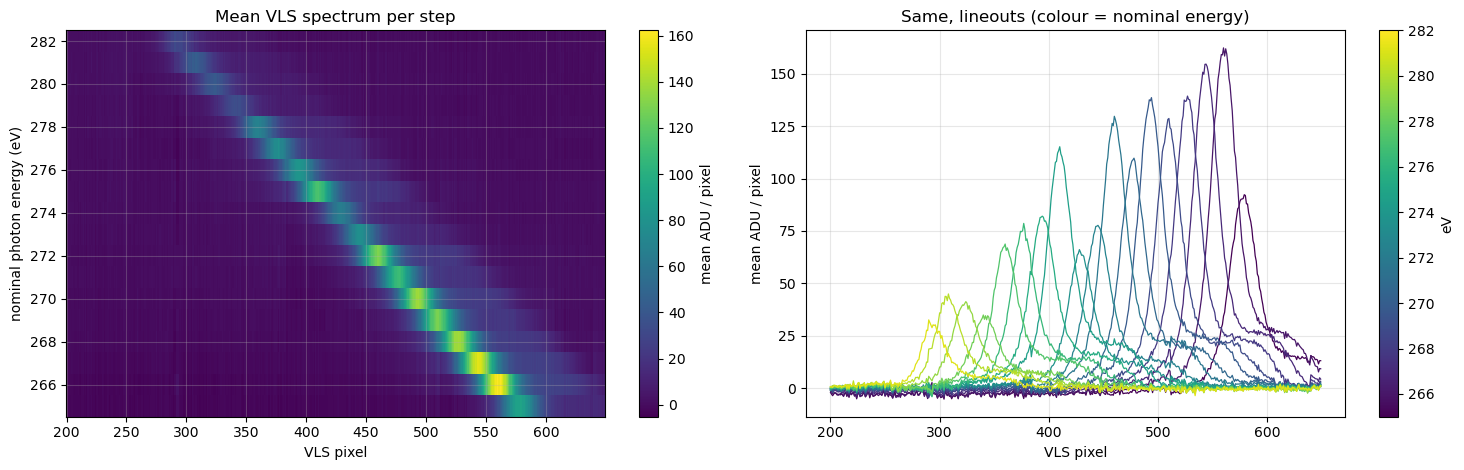

In [5]:
cols = mpl.colormaps["viridis"](np.linspace(0, 0.95, len(steps)))
e_edges_nom = np.r_[steps[0] - 0.5 * np.diff(steps)[:1], 0.5 * (steps[1:] + steps[:-1]),
                    steps[-1] + 0.5 * np.diff(steps)[-1:]]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
mesh = axs[0].pcolormesh(px, steps, spec, shading="nearest", cmap="viridis")
fig.colorbar(mesh, ax=axs[0], label="mean ADU / pixel")
axs[0].set(xlabel="VLS pixel", ylabel="nominal photon energy (eV)", title="Mean VLS spectrum per step")
for s, E, c in zip(spec, steps, cols):
    axs[1].plot(px, s, color=c, lw=0.9)
axs[1].set(xlabel="VLS pixel", ylabel="mean ADU / pixel", title="Same, lineouts (colour = nominal energy)")
fig.colorbar(mpl.cm.ScalarMappable(Normalize(steps.min(), steps.max()), "viridis"), ax=axs[1], label="eV")
fig.tight_layout()
plt.show()

## 3. Pixel → eV calibration and measured photon energy

Peak position of each step's mean spectrum (same estimator as for single shots) against its nominal energy, fitted with
a polynomial of order `CAL_ORDER`. `E_meas` is the calibrated centre of every shot with `vls_ok`. The scan trace shows the
nominal energy per train and the median measured energy per train; grey = trains dropped while settling.

calibration E(px) = -0.0596818 px^1 + 299.524 px^0
slope -0.0597 eV/px, rms residual 0.076 eV
step: centre of mean spectrum / median single-shot centre (px):
  265: 579.0/578.6, 266: 561.2/560.8, 267: 544.7/544.3, 268: 527.5/527.4, 269: 510.8/510.7, 270: 494.0/494.1, 271: 478.0/477.9, 272: 460.9/461.0, 273: 446.1/446.1, 274: 430.2/430.2, 275: 411.0/411.2, 276: 395.0/395.0, 277: 377.3/377.1, 278: 361.4/361.1, 279: 342.5/342.1, 280: 324.4/324.2, 281: 308.9/308.8, 282: 296.0/295.7


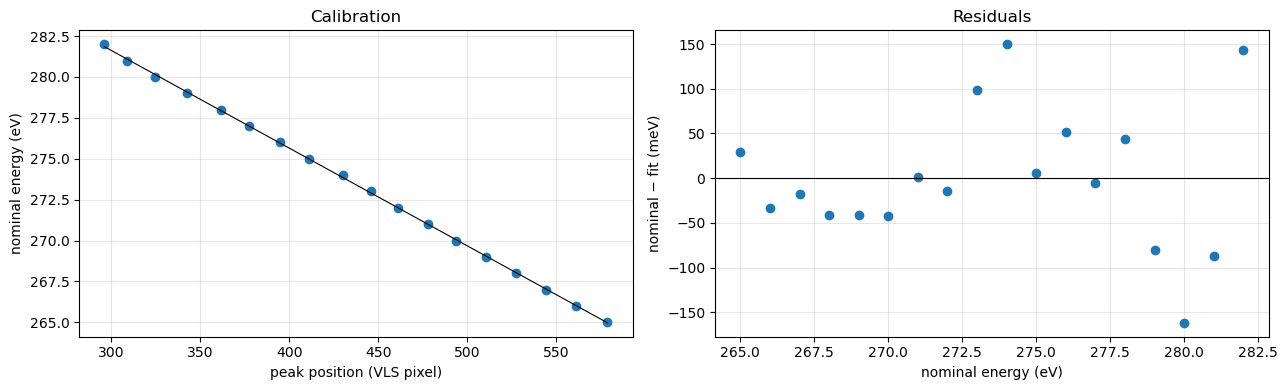

In [6]:
def centre_of(s):
    sm = uniform_filter1d(s, VLS_SMOOTH, mode="nearest")
    w = np.abs(px - px[np.argmax(sm)]) <= CENTRE_HALF_WIDTH
    c = np.clip(s, 0, None) * w
    return (c * px).sum() / c.sum()


cent_step = np.array([centre_of(s) for s in spec])
coef = np.polyfit(cent_step, steps, CAL_ORDER)
resid = steps - np.polyval(coef, cent_step)
E_meas = np.where(vls_ok, np.polyval(coef, vls_centre), np.nan)
med_shot_cent = np.array([np.nanmedian(np.where(shot & vls_ok, vls_centre, np.nan)[step_of == k]) for k in range(len(steps))])
print("calibration E(px) = " + " + ".join(f"{c:.6g} px^{len(coef) - 1 - i}" for i, c in enumerate(coef)))
print(f"slope {np.polyval(np.polyder(coef), cent_step.mean()):.4f} eV/px, rms residual {np.sqrt(np.mean(resid**2)):.3f} eV")
print("step: centre of mean spectrum / median single-shot centre (px):")
print("  " + ", ".join(f"{E:.0f}: {c:.1f}/{s:.1f}" for E, c, s in zip(steps, cent_step, med_shot_cent)))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(cent_step, steps, "o")
pp = np.linspace(cent_step.min(), cent_step.max(), 100)
axs[0].plot(pp, np.polyval(coef, pp), "k-", lw=0.8)
axs[0].set(xlabel="peak position (VLS pixel)", ylabel="nominal energy (eV)", title="Calibration")
axs[1].plot(steps, resid * 1e3, "o")
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set(xlabel="nominal energy (eV)", ylabel="nominal − fit (meV)", title="Residuals")
fig.tight_layout()
plt.show()

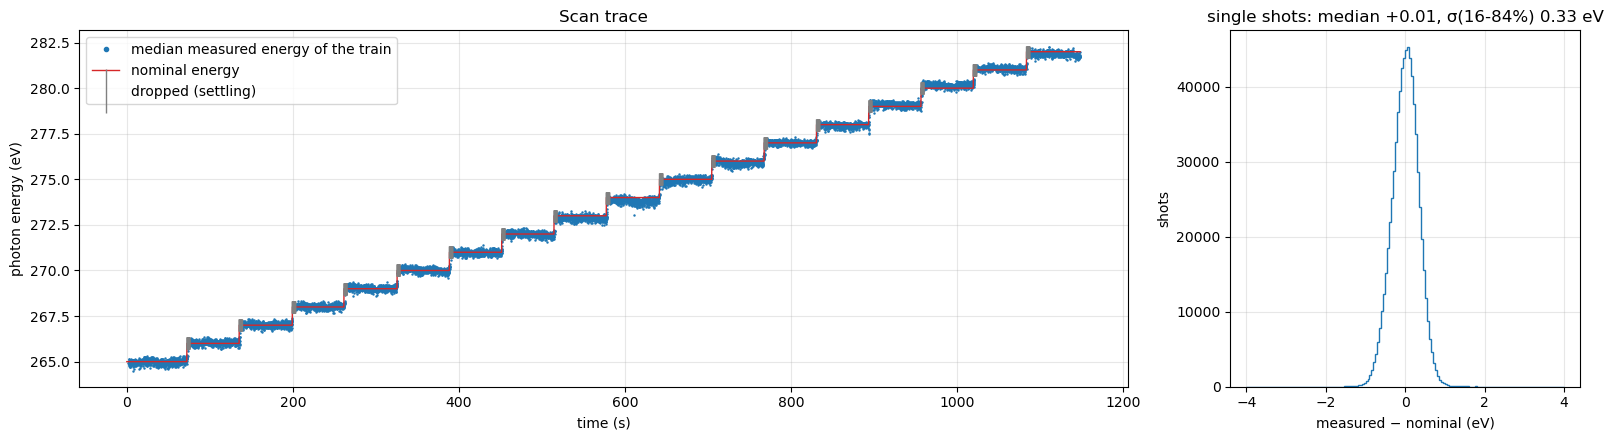

In [7]:
E_meas_train = np.nanmedian(np.where(pulse & in_range, E_meas, np.nan), axis=1)
dE = (E_meas - E_nom[:, None])[shot & vls_ok]
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
axs[0].plot(t_s, E_meas_train, ".", ms=1.5, color="C0", label="median measured energy of the train")
axs[0].plot(t_s, E_nom, "-", color="C3", lw=1, label="nominal energy")
settling = np.isfinite(E_nom) & (since_change < SETTLE_TRAINS)
axs[0].plot(t_s[settling], E_nom[settling], "|", color="0.5", ms=8, label="dropped (settling)")
axs[0].set(xlabel="time (s)", ylabel="photon energy (eV)", title="Scan trace")
axs[0].legend(loc="upper left", markerscale=4)
axs[1].hist(dE, bins=np.arange(-4, 4.01, 0.05), histtype="step")
axs[1].set(xlabel="measured − nominal (eV)", ylabel="shots",
           title=f"single shots: median {np.median(dE):+.2f}, σ(16-84%) {np.diff(np.percentile(dE, [16, 84]))[0] / 2:.2f} eV")
fig.tight_layout()
plt.show()

## 4. Electron TOF vs nominal photon energy

All hits of the shots used (`shot`), summed per step and divided by the summed GMD (`NORMALISE = "gmd"`) or the number
of shots (`"shot"`).

hits per shot per step: [0.273, 0.427, 0.396, 0.422, 0.382, 0.413, 0.325, 0.378, 0.238, 0.205, 0.343, 0.257, 0.224, 0.204, 0.112, 0.128, 0.135, 0.096]


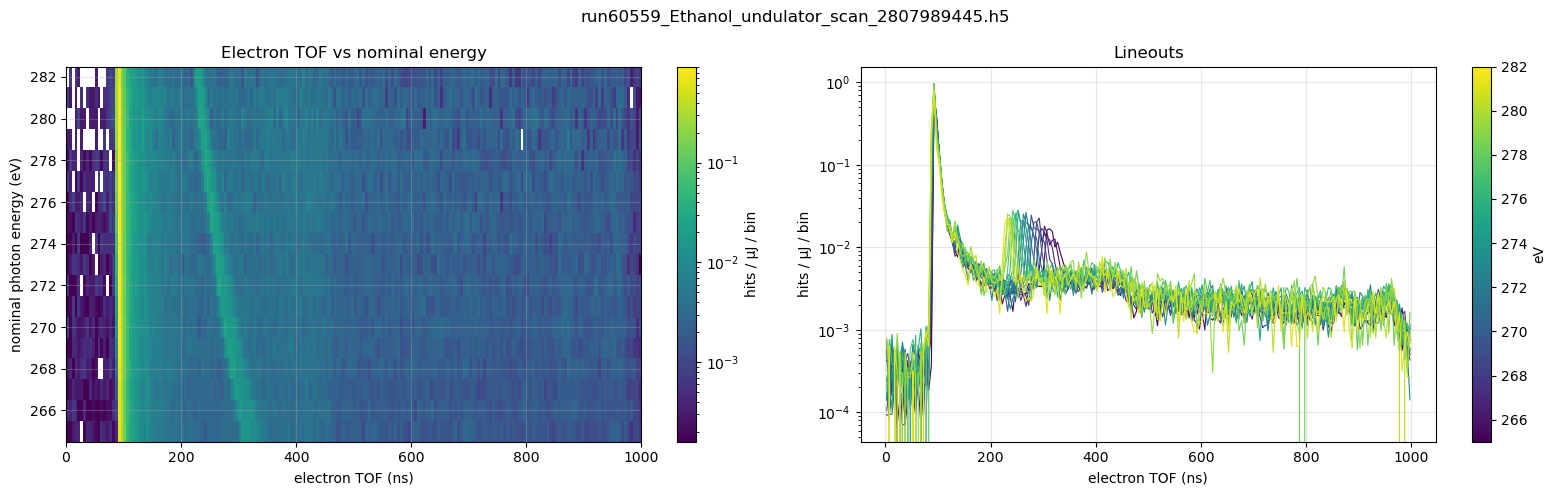

In [8]:
tof_edges = np.arange(E_TOF_RANGE[0], E_TOF_RANGE[1] + E_TOF_BIN, E_TOF_BIN)
tof_cent = 0.5 * (tof_edges[1:] + tof_edges[:-1])
# Hit list of the electron TOF: train, slot and TOF of every hit
tr_e, sl_e, k_e = np.nonzero(He > 0)
t_e = He[tr_e, sl_e, k_e]
use_e = shot[tr_e, sl_e]

counts_nom = np.zeros((len(steps), len(tof_cent)))
for k in range(len(steps)):
    m = use_e & (step_of[tr_e] == k)
    counts_nom[k] = np.histogram(t_e[m], tof_edges)[0]
n_nom = np.array([shot[step_of == k].sum() for k in range(len(steps))])
g_nom = np.array([np.nansum(gmd[step_of == k][shot[step_of == k]]) for k in range(len(steps))])
den_nom = g_nom if NORMALISE == "gmd" else n_nom
ylab = "hits / µJ / bin" if NORMALISE == "gmd" else "hits / shot / bin"
spec_nom = counts_nom / den_nom[:, None]
print("hits per shot per step:", np.round(counts_nom.sum(1) / n_nom, 3).tolist())

def tof_norm(a):
    pos = a[np.isfinite(a) & (a > 0)]
    return LogNorm(*np.percentile(pos, [1, 99.9])) if LOG_MAPS else Normalize(0, np.percentile(pos, 99.9))

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
mesh = axs[0].pcolormesh(tof_edges, e_edges_nom, spec_nom, norm=tof_norm(spec_nom), cmap="viridis")
fig.colorbar(mesh, ax=axs[0], label=ylab)
axs[0].set(xlabel="electron TOF (ns)", ylabel="nominal photon energy (eV)", title="Electron TOF vs nominal energy")
for s, c in zip(spec_nom, cols):
    axs[1].plot(tof_cent, s, color=c, lw=0.8)
axs[1].set(xlabel="electron TOF (ns)", ylabel=ylab, yscale="log" if LOG_MAPS else "linear", title="Lineouts")
fig.colorbar(mpl.cm.ScalarMappable(Normalize(steps.min(), steps.max()), "viridis"), ax=axs[1], label="eV")
fig.suptitle(h5_path.name)
fig.tight_layout()
plt.show()

## 5. Electron TOF vs measured photon energy

The same hits, now binned on the measured energy of their own shot (`E_meas`, shots with `vls_ok` only), in bins of
`E_MEAS_BIN`. Right: shots per bin; bins with fewer than `MIN_SHOTS_PER_BIN` are left blank.

732521 shots with a measured energy; 75 bins of 0.25 eV with at least 200 shots


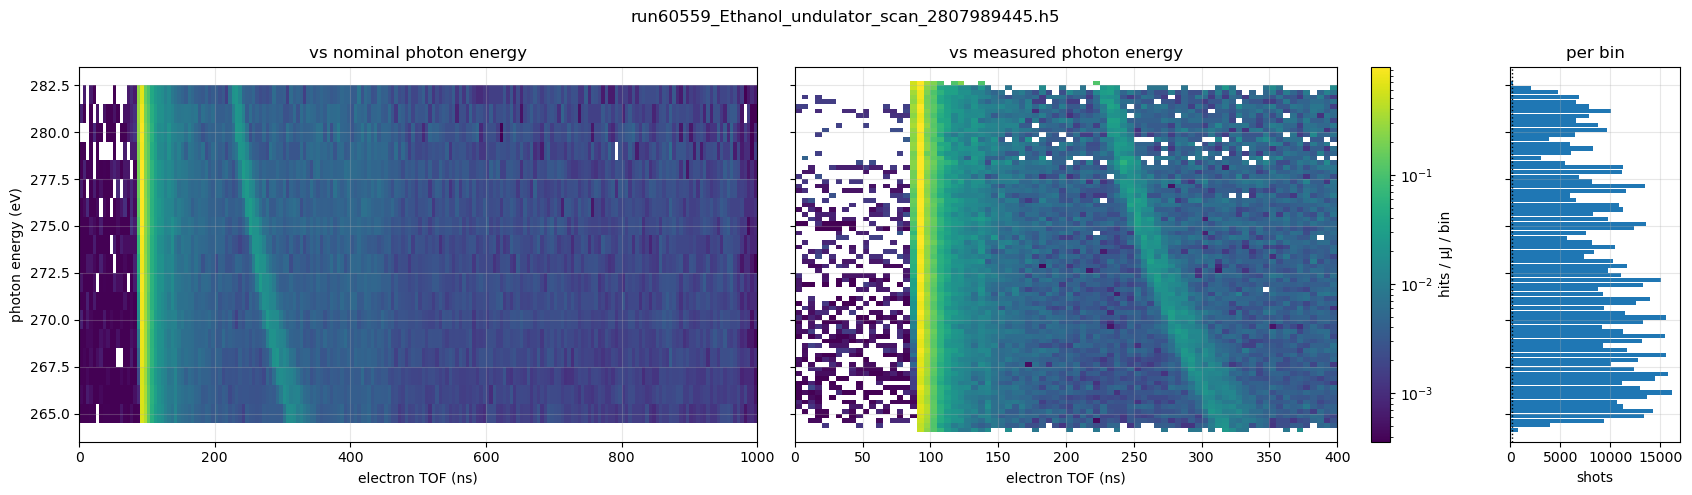

In [28]:
lo, hi = E_MEAS_RANGE or (steps.min() - 1.5, steps.max() + 1.5)
em_edges = np.arange(lo, hi + E_MEAS_BIN / 2, E_MEAS_BIN)
em_cent = 0.5 * (em_edges[1:] + em_edges[:-1])
sel = shot & vls_ok
b_shot = np.full((n_trains, n_slots), -1)
b_shot[sel] = np.digitize(E_meas[sel], em_edges) - 1
b_shot[(b_shot < 0) | (b_shot >= len(em_cent))] = -1
n_meas = np.bincount(b_shot[b_shot >= 0], minlength=len(em_cent))
g_meas = np.bincount(b_shot[b_shot >= 0], weights=gmd[b_shot >= 0], minlength=len(em_cent))
b_hit = b_shot[tr_e, sl_e]
counts_meas = np.histogram2d(b_hit[b_hit >= 0], t_e[b_hit >= 0],
                             bins=(np.arange(len(em_cent) + 1) - 0.5, tof_edges))[0]
den_meas = g_meas if NORMALISE == "gmd" else n_meas
spec_meas = counts_meas / den_meas[:, None]
spec_meas[n_meas < MIN_SHOTS_PER_BIN] = np.nan
print(f"{sel.sum()} shots with a measured energy; {(n_meas >= MIN_SHOTS_PER_BIN).sum()} bins of {E_MEAS_BIN} eV "
      f"with at least {MIN_SHOTS_PER_BIN} shots")

fig, axs = plt.subplots(1, 3, figsize=(17, 5), sharey=True, gridspec_kw={"width_ratios": [4, 4, 1]})
for ax, (sp, edges, lab) in zip(axs, [(spec_nom, e_edges_nom, "nominal"), (spec_meas, em_edges, "measured")]):
    mesh = ax.pcolormesh(tof_edges, edges, sp, norm=tof_norm(spec_meas), cmap="viridis")
    ax.set(xlabel="electron TOF (ns)", title=f"vs {lab} photon energy")
axs[0].set_ylabel("photon energy (eV)")
fig.colorbar(mesh, ax=axs[1], label=ylab)
axs[2].barh(em_cent, n_meas, height=E_MEAS_BIN * 0.9)
axs[2].axvline(MIN_SHOTS_PER_BIN, color="k", ls=":", lw=1)
axs[2].set(xlabel="shots", title="per bin")
fig.suptitle(h5_path.name)
fig.tight_layout()
axs[1].set_xlim(0, 400)
plt.show()

## 6. Average train at each nominal energy

Bunch slot × electron TOF, ion TOF and VLS pixel, averaged over the trains of each step (all slots, the trains in `good`).
`TRAIN_MAP_NORM = None`: per train; `"gmd"`: per µJ of the pulses in each slot. One colour scale per detector; dashed
lines mark `BUNCH_RANGE`.

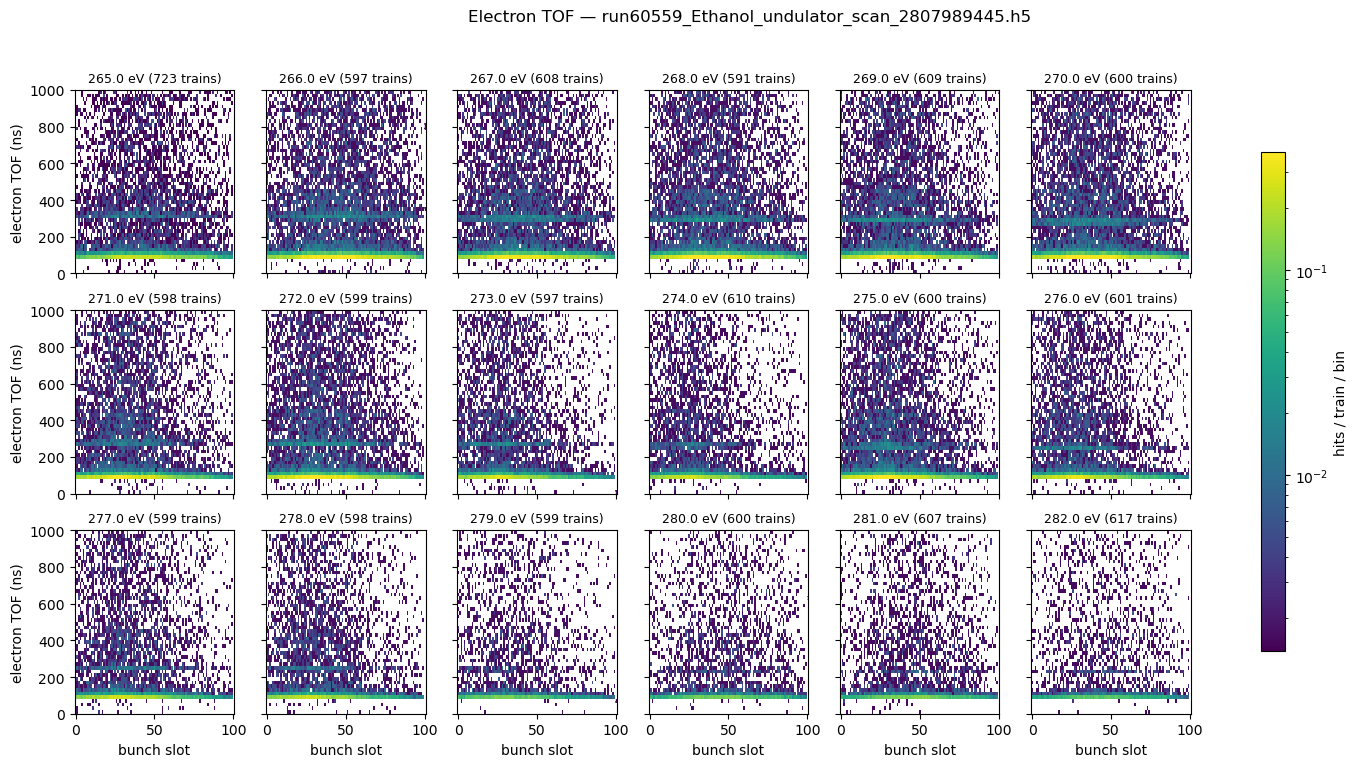

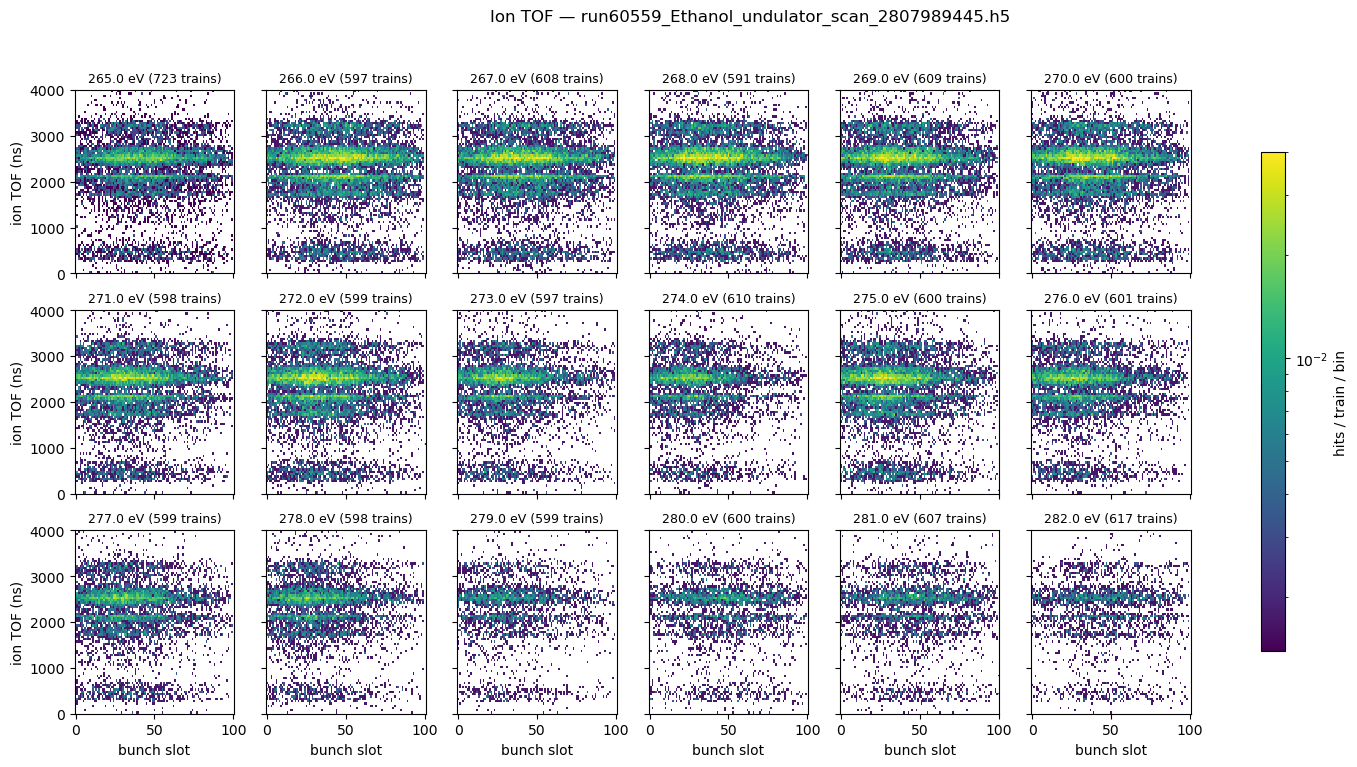

In [10]:
slot_edges = np.arange(n_slots + 1) - 0.5
n_tr_step = np.array([(step_of == k).sum() for k in range(len(steps))])
g_slot_step = np.array([np.nansum(gmd[step_of == k], axis=0) for k in range(len(steps))])   # (n_steps, n_slots)


def hit_maps(H, rng):
    # (n_steps, n_slots, n_bins) hits per train or per µJ in each slot
    edges = np.arange(rng[0], rng[1] + rng[2], rng[2])
    tr, sl, kk = np.nonzero((H > rng[0]) & (H < rng[1]))
    t = H[tr, sl, kk]
    st = step_of[tr]
    maps = np.stack([np.histogram2d(sl[st == k], t[st == k], bins=(slot_edges, edges))[0] for k in range(len(steps))])
    den = g_slot_step if TRAIN_MAP_NORM == "gmd" else np.repeat(n_tr_step[:, None], n_slots, axis=1)
    return edges, maps / np.where(den > 0, den, np.nan)[..., None]


def map_grid(edges, maps, norm, ylabel, clabel, title):
    nrow = int(np.ceil(len(steps) / MAP_COLS))
    fig, axs = plt.subplots(nrow, MAP_COLS, figsize=(3 * MAP_COLS, 2.7 * nrow), sharex=True, sharey=True,
                            squeeze=False)
    for ax in axs.flat[len(steps):]:
        ax.set_visible(False)
    for k, ax in enumerate(axs.flat[:len(steps)]):
        mesh = ax.pcolormesh(slot_edges, edges, maps[k].T, norm=norm, cmap="viridis")
        ax.grid(False)
        for b in BUNCH_RANGE:
            ax.axvline(b - 0.5, color="w", ls="--", lw=0.6)
        ax.set_title(f"{steps[k]:.1f} eV ({n_tr_step[k]} trains)", fontsize=9)
    for ax in axs[-1]:
        ax.set_xlabel("bunch slot")
    for ax in axs[:, 0]:
        ax.set_ylabel(ylabel)
    fig.colorbar(mesh, ax=axs, label=clabel, shrink=0.8)
    fig.suptitle(f"{title} — {h5_path.name}")
    plt.show()


unit = "µJ" if TRAIN_MAP_NORM == "gmd" else "train"
edges_e, maps_e = hit_maps(He, MAP_E_TOF)
map_grid(edges_e, maps_e, tof_norm(maps_e), "electron TOF (ns)", f"hits / {unit} / bin", "Electron TOF")
edges_i, maps_i = hit_maps(Hi, MAP_I_TOF)
map_grid(edges_i, maps_i, tof_norm(maps_i), "ion TOF (ns)", f"hits / {unit} / bin", "Ion TOF")

In [13]:
tof_norm?

Signature: tof_norm(a)
Docstring: <no docstring>
File:      /tmp/ipykernel_2535607/2510586085.py
Type:      function

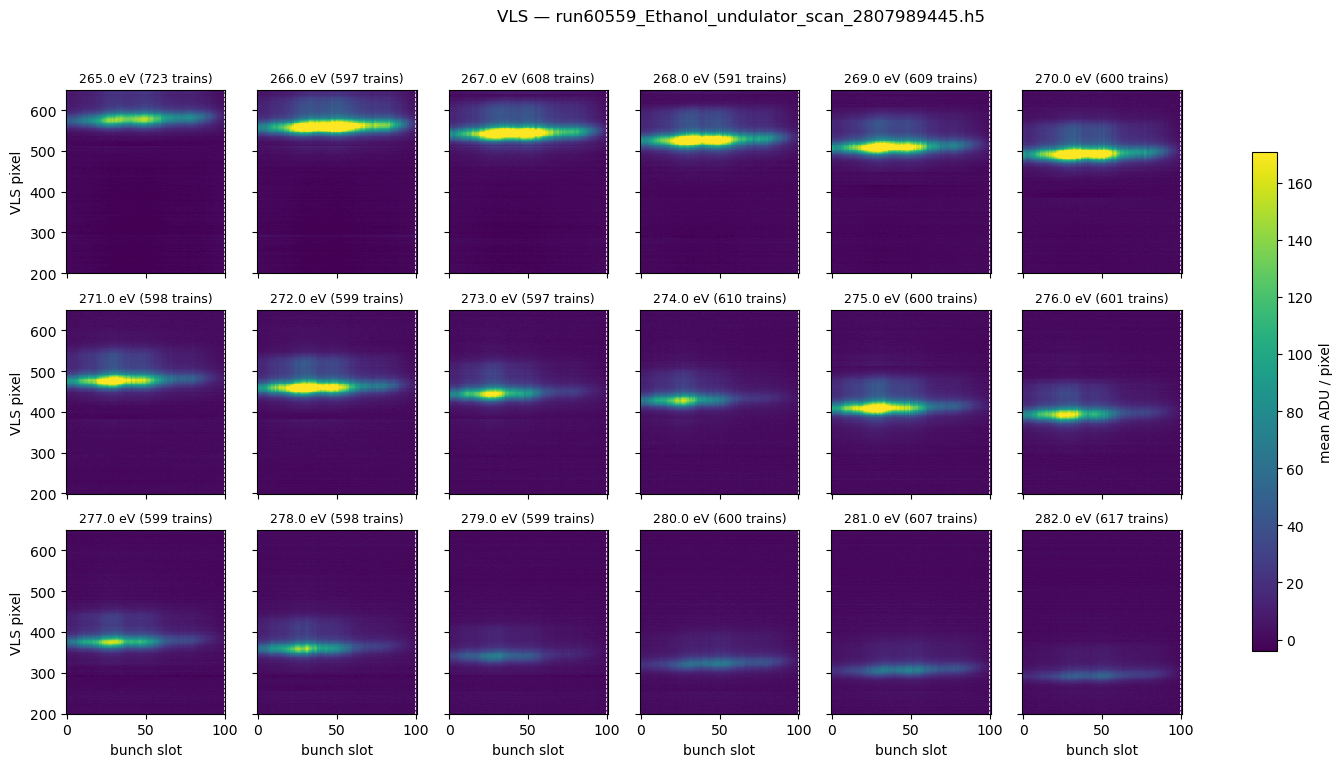

In [11]:
nb_px = len(px) // MAP_VLS_BIN * MAP_VLS_BIN
px_edges = np.r_[px[:nb_px:MAP_VLS_BIN] - 0.5, px[nb_px - 1] + 0.5]
vmaps = vls_step[:, :, :nb_px].reshape(len(steps), n_slots, -1, MAP_VLS_BIN).mean(-1)
den = g_vls_step if TRAIN_MAP_NORM == "gmd" else np.repeat(n_vls_step[:, None], n_slots, axis=1)
vmaps = vmaps / np.where(den > 0, den, np.nan)[..., None]
finite = vmaps[np.isfinite(vmaps)]
map_grid(px_edges, vmaps, Normalize(*np.percentile(finite, [1, 99.5])), "VLS pixel",
         "ADU / pixel / µJ" if TRAIN_MAP_NORM == "gmd" else "mean ADU / pixel", "VLS")

In [16]:
maps_i.shape, vmaps.shape

((18, 101, 80), (18, 101, 224))

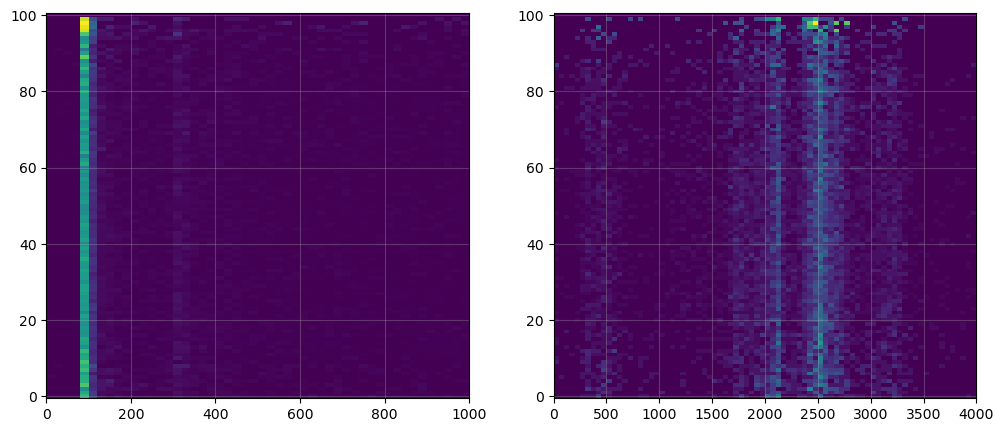

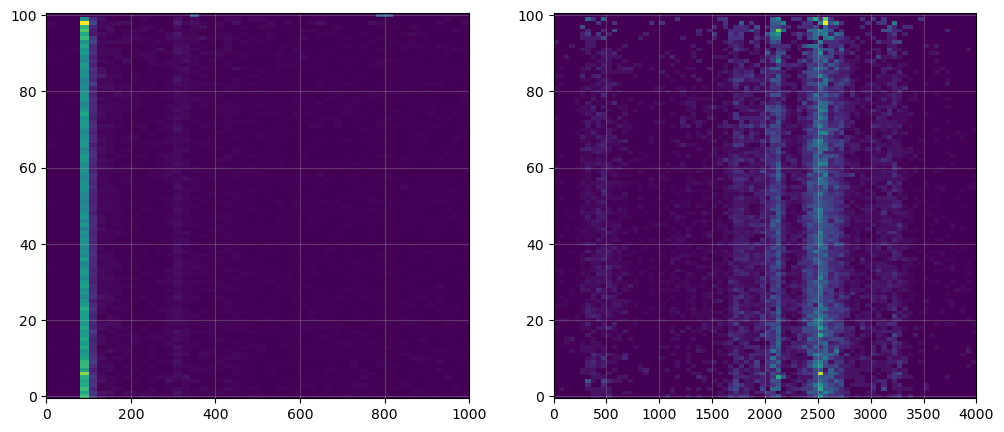

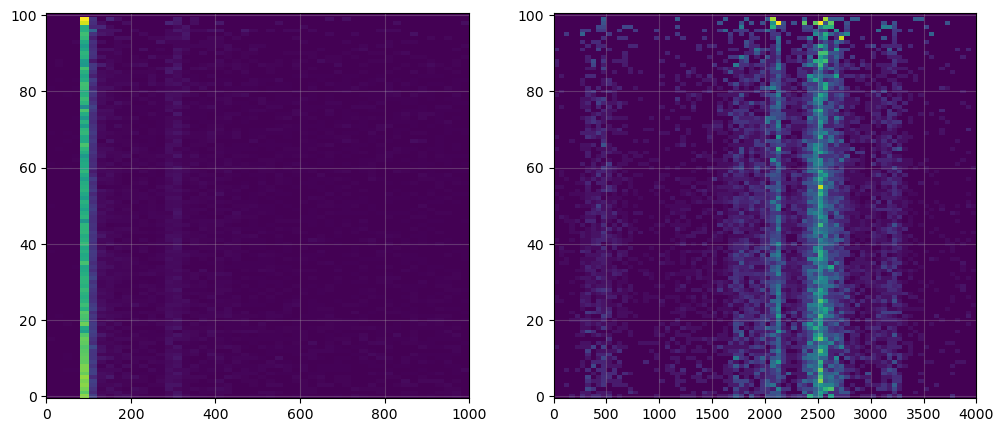

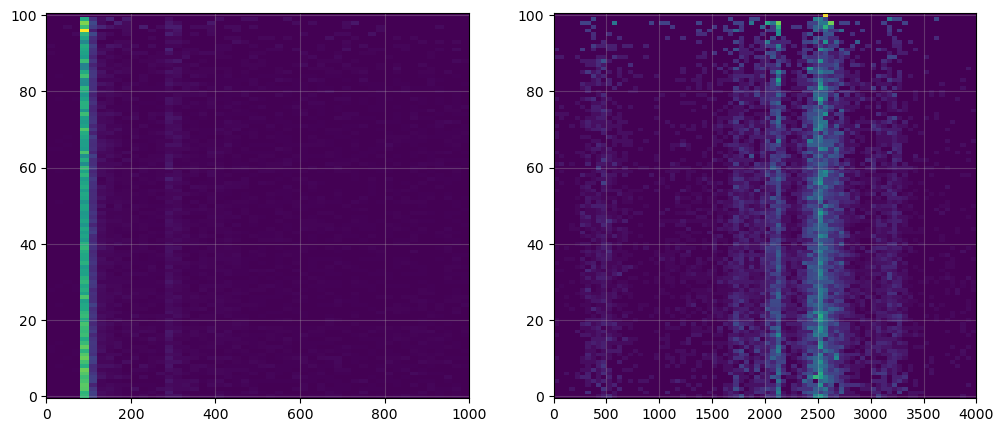

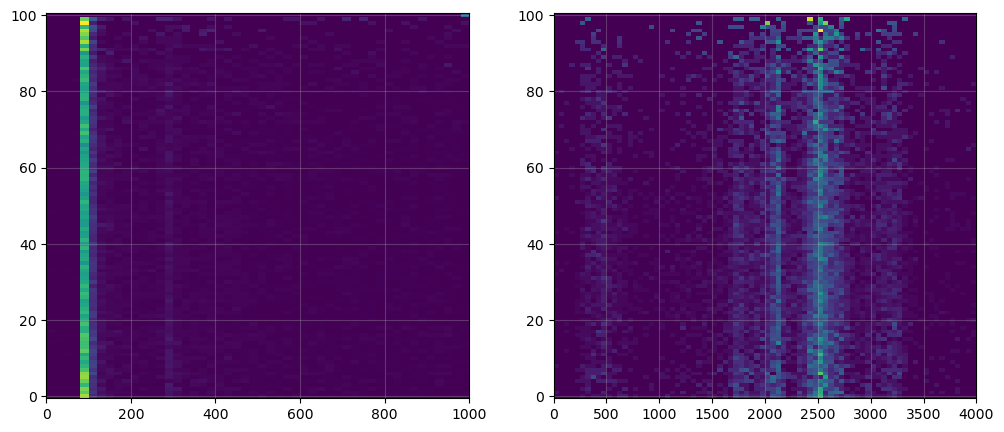

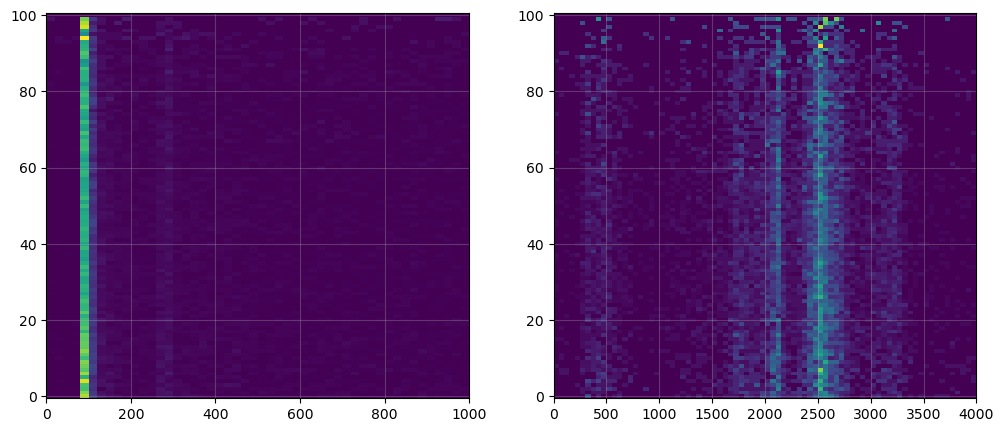

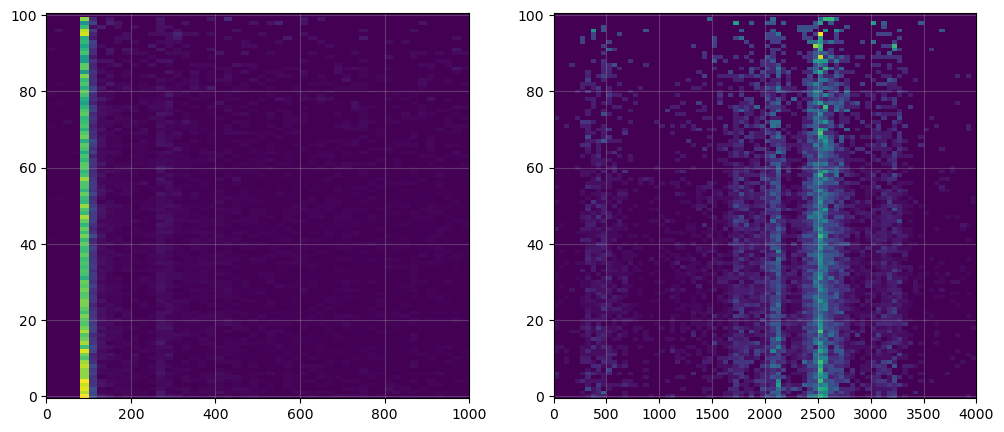

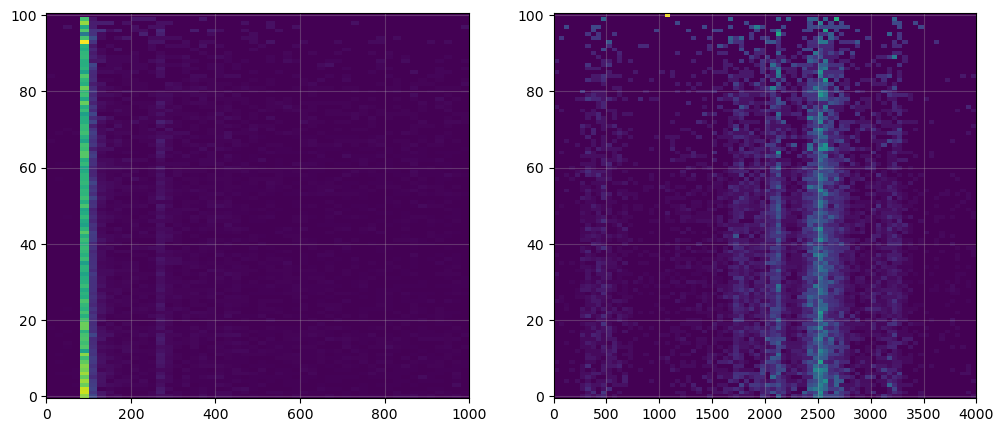

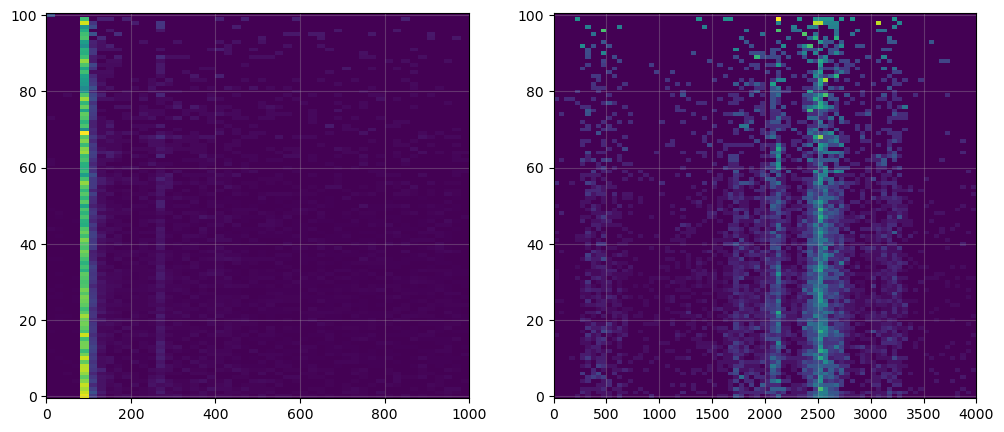

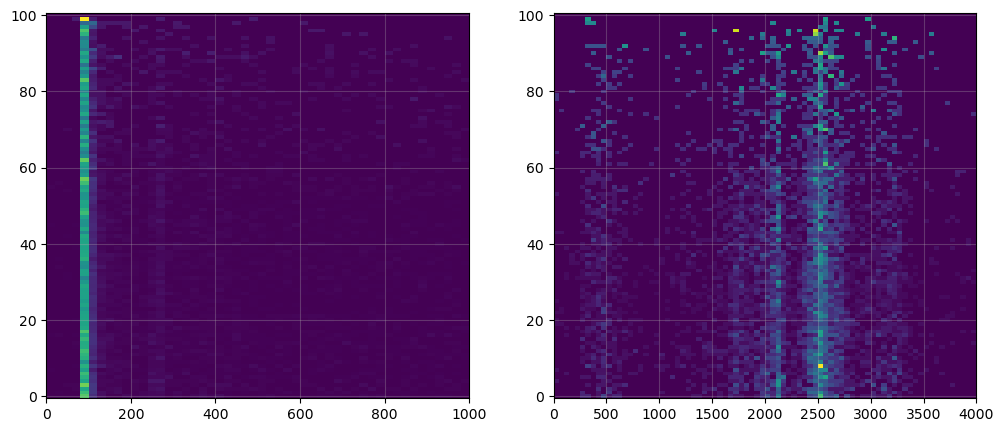

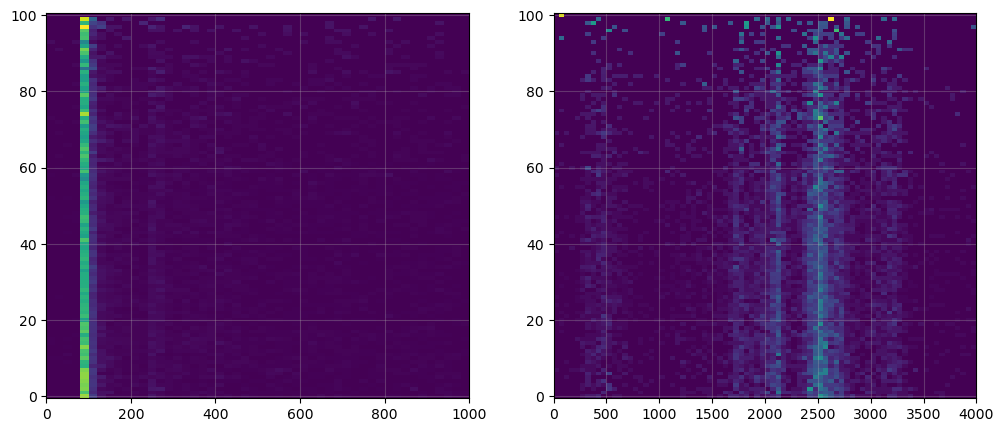

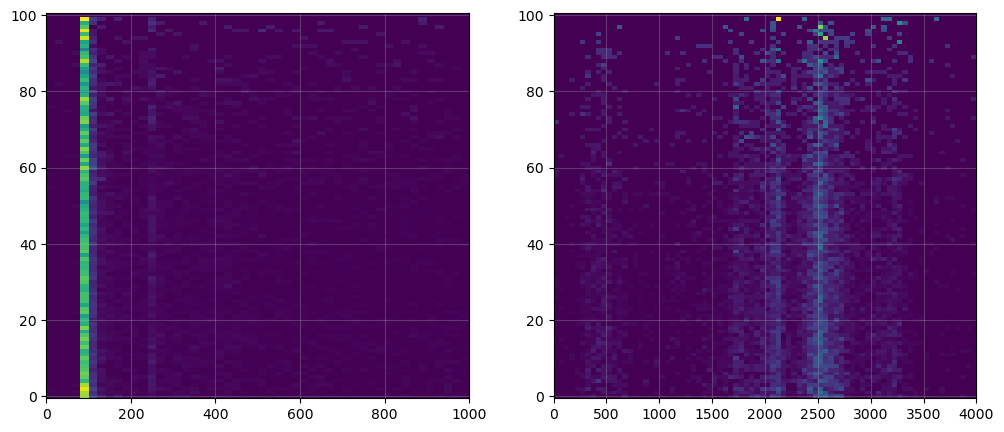

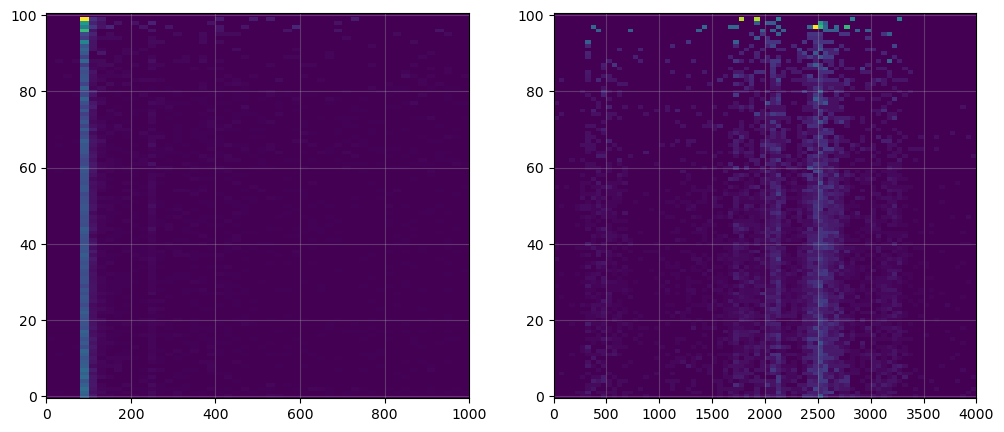

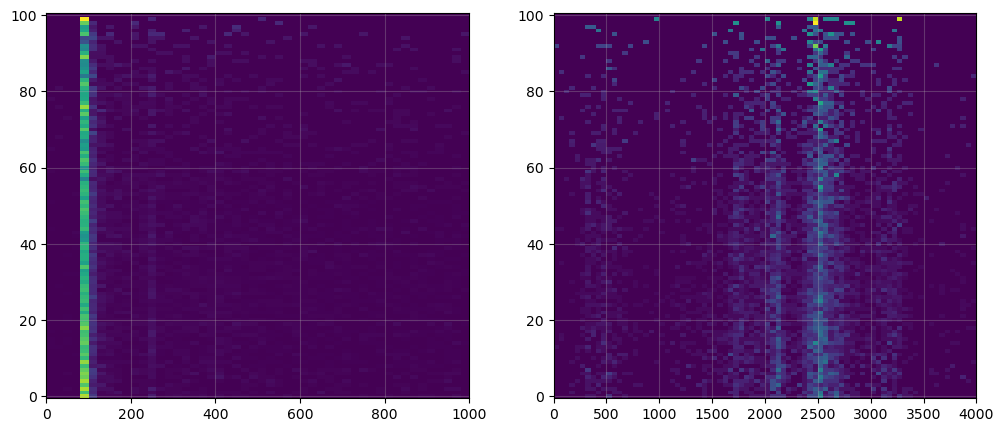

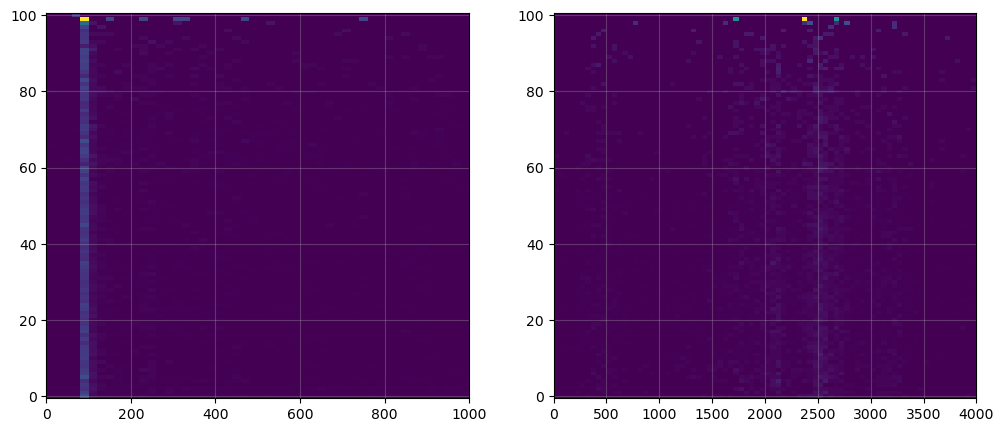

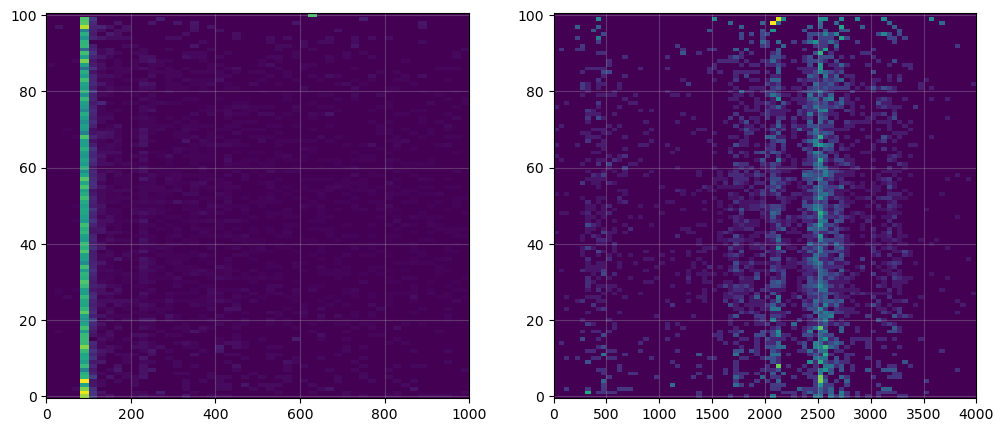

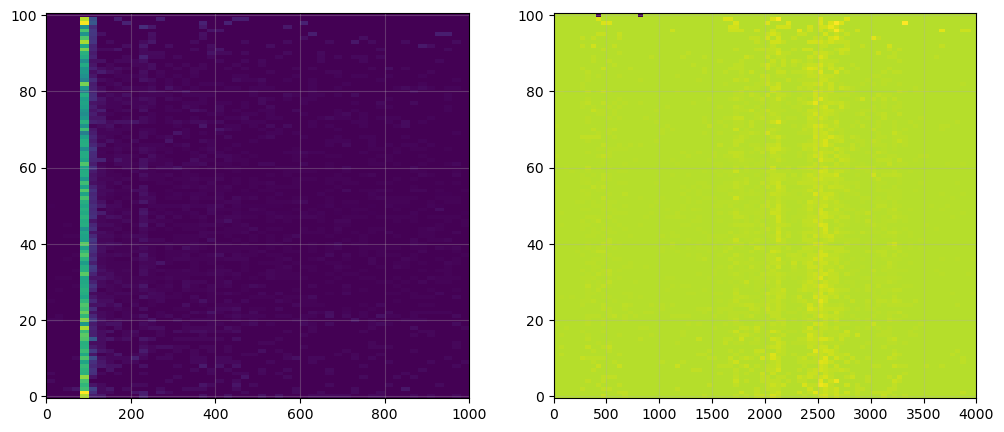

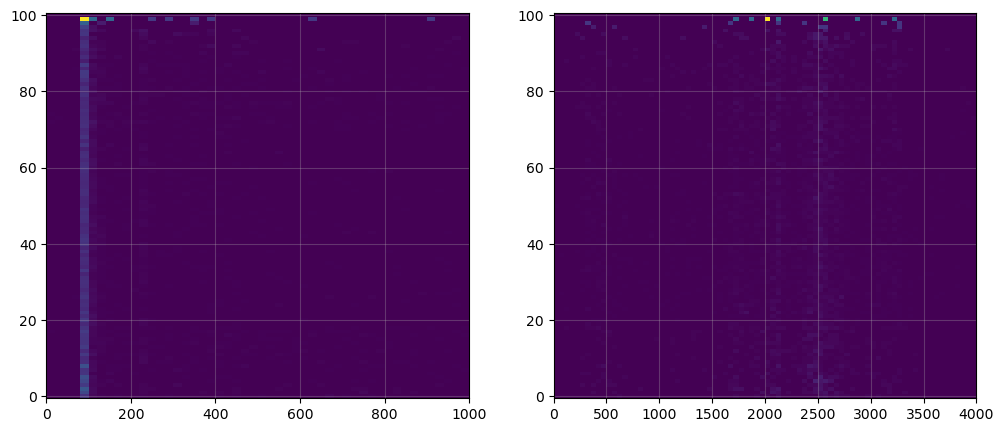

In [25]:
for map_i, map_e, map_v in zip(maps_i, maps_e, vmaps):
    fig, ax = plt.subplots(1,2, figsize=(12,5))
    ax=ax.flatten()

    # mesh0 = ax[0].pcolormesh(map_i)
    # mesh1 = ax[1].pcolormesh(map_e)
    # mesh2 = ax[2].pcolormesh(map_v)
    mesh0 = ax[0].pcolormesh(edges_e, slot_edges, map_e/map_v.sum(1)[:, np.newaxis])
    mesh1 = ax[1].pcolormesh(edges_i, slot_edges, map_i/map_v.sum(1)[:, np.newaxis])
    